# Isolation Forest
- Three general steps:
> - 1. Model development.
> - 2. Threshold determination.
> - 3. Profiling normal and abnormal groups.

In [67]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# from matplotlib import pyplot as plt
from pyod.models.iforest import IForest
# from sklearn.ensemble import IsolationForest # Note: In sklearn IsolationForest, lower scores = more anomalous.
import optuna
from sklearn.metrics import average_precision_score
import shap

from pyod.models.combination import aom, moa, average, maximization
from pyod.utils.utility import standardizer


from src.ML_Utils import (DGP, plot_generated_data, plot_hist, count_stat,
                          evaluate_model, descriptive_stat_threshold, confusion_matrix)

NETWORK_TRAFFIC_PATH = Path.cwd().parent / "data" / "network_traffic" 
NETWORK_TRAFFIC_TRAIN = NETWORK_TRAFFIC_PATH / "df_train.csv"
NETWORK_TRAFFIC_VALID = NETWORK_TRAFFIC_PATH / "df_valid.csv"
NETWORK_TRAFFIC_TEST = NETWORK_TRAFFIC_PATH / "df_hold.csv"

## Load data

In [8]:
df_train = pd.read_csv(NETWORK_TRAFFIC_TRAIN)
X_train = df_train.drop("label", axis=1)
y_train = df_train['label']
print(y_train)
X_train.head()

0      0.0
1      0.0
2      1.0
3      0.0
4      0.0
      ... 
695    0.0
696    0.0
697    0.0
698    0.0
699    0.0
Name: label, Length: 700, dtype: float64


,packet_size,inter_arrival_time,src_port,dst_port,packet_count_5s,mean_packet_size,spectral_entropy,frequency_band_energy,protocol_type_TCP,protocol_type_UDP,src_ip_192.168.1.2,src_ip_192.168.1.3,dst_ip_192.168.1.5,dst_ip_192.168.1.6,tcp_flags_FIN,tcp_flags_SYN,tcp_flags_SYN-ACK
0,0.130995,0.325352,64796,80,0.714286,0.0,0.836820,0.621469,False,True,False,False,True,False,False,True,False
1,0.983536,0.341513,25476,443,0.357143,0.0,0.109997,0.462735,True,False,False,False,False,False,True,False,False
2,0.040086,0.812864,7022,80,0.071429,0.0,0.506324,0.734016,True,False,True,False,True,False,False,False,False
3,0.928418,0.725507,60573,80,0.000000,0.0,0.914045,0.923464,True,False,False,False,False,True,False,False,False
4,0.545455,0.323503,30487,53,0.571429,0.0,0.992607,0.590219,False,False,True,False,False,False,False,False,False


In [18]:
df_valid= pd.read_csv(NETWORK_TRAFFIC_VALID)
X_valid = df_valid.drop("label", axis=1)
y_valid = df_valid['label']

In [17]:
df_test= pd.read_csv(NETWORK_TRAFFIC_TEST)
X_test = df_test.drop("label", axis=1)
y_test = df_test['label']

## Step 1: Build the model

In [14]:
help(IForest)

Help on class IForest in module pyod.models.iforest:

class IForest(pyod.models.base.BaseDetector)
 |  IForest(n_estimators=100, max_samples='auto', contamination=0.1, max_features=1.0, bootstrap=False, n_jobs=1, behaviour='old', random_state=None, verbose=0)
 |
 |  Wrapper of scikit-learn Isolation Forest with more functionalities.
 |
 |  The IsolationForest 'isolates' observations by randomly selecting a
 |  feature and then randomly selecting a split value between the maximum and
 |  minimum values of the selected feature.
 |  See :cite:`liu2008isolation,liu2012isolation` for details.
 |
 |  Since recursive partitioning can be represented by a tree structure, the
 |  number of splittings required to isolate a sample is equivalent to the path
 |  length from the root node to the terminating node.
 |
 |  This path length, averaged over a forest of such random trees, is a
 |  measure of normality and our decision function.
 |
 |  Random partitioning produces noticeably shorter paths fo

In [ ]:
# Using smaller subsamples to construct trees can further enhance the algorithm’s effectiveness. 
# Smaller samples reduce masking effects, where normal observations obscure anomalies, 
# thereby making anomalous points easier to isolate.

# simple fitting
# isft = IForest(contamination=0.05, max_samples=0.4, behaviour='new', random_state=42)
# isft.fit(X_train)
# print out params
# isft.get_params()
# feature importance and plot
# isft_vi = isft.feature_importances_
# isft_vi
# for_plot = pd.DataFrame({'x_axis':X_train.columns, 'y_axis':isft_vi}).sort_values(by='y_axis',ascending=True)
# for_plot['y_axis'].plot.barh()

# results = {
#         "train_scores": model.decision_function(X_train),
#         "train_pred": model.predict(X_train),
#         "test_scores": model.decision_function(X_test),
#         "test_pred": model.predict(X_test),
#         "threshold": getattr(model, "threshold_", None)
#     }

In [19]:
# HYPERPARAMETER TUNING WITH OPTUNA 
# WITH LABELED VALIDATION SET 
def objective(trial):
  params = {
      "n_estimators": trial.suggest_int("n_estimators", 50, 500),
      "contamination":trial.suggest_float("contamination", 0.01, 0.5),
      "max_samples": trial.suggest_float("max_samples", 0.1, 1.0),
      "max_features": trial.suggest_float("max_features", 0.1, 1.0),
      "bootstrap": trial.suggest_categorical("bootstrap", [True, False]),
      "behaviour": 'new',
      "random_state": 42,
      "n_jobs": -1,
  }

  # skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
  # scores = []

  # for train_idx, val_idx in skf.split(X, y):
  # X_tr, y_tr = X[train_idx], y[train_idx]
  # X_va, y_va = X[val_idx], y[val_idx]

  # Optional: Train only on normal samples (semi-supervised / novelty detection)
  # X_tr = X_tr[y_tr == 0]

  model = IForest(**params)
  model.fit(X_train)

  # Negate scores so higher = more anomalous
  anomaly_scores = model.predict(X_valid)

  # PR-AUC (average_precision_score) is preferred for heavily imbalanced anomalies
  pr_auc_score = average_precision_score(y_valid, anomaly_scores)
  # scores.append(score)

  return pr_auc_score


study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=50)

print("Best PR-AUC:", study.best_value)
print("Best Params:", study.best_params)


[I 2026-11-26 13:37:19,122] A new study created in memory with name: no-name-15d8f11c-2c95-47d1-ac7e-22377682cd80
[I 2026-11-26 13:37:20,691] Trial 0 finished with value: 0.11504950495049504 and parameters: {'n_estimators': 340, 'contamination': 0.48995729006566974, 'max_samples': 0.8888391558877585, 'max_features': 0.4443516579976129, 'bootstrap': True}. Best is trial 0 with value: 0.11504950495049504.
[I 2026-11-26 13:37:22,046] Trial 1 finished with value: 0.14028169014084507 and parameters: {'n_estimators': 440, 'contamination': 0.3203136686833407, 'max_samples': 0.7504320984908376, 'max_features': 0.32025208917924236, 'bootstrap': True}. Best is trial 1 with value: 0.14028169014084507.
[I 2026-11-26 13:37:23,189] Trial 2 finished with value: 0.11166666666666666 and parameters: {'n_estimators': 402, 'contamination': 0.3350933768731221, 'max_samples': 0.11255617874222945, 'max_features': 0.7932153658827171, 'bootstrap': True}. Best is trial 1 with value: 0.14028169014084507.
[I 2026

Best PR-AUC: 0.15333333333333332
Best Params: {'n_estimators': 376, 'contamination': 0.32383094237056026, 'max_samples': 0.7975439150431451, 'max_features': 0.34182681748898264, 'bootstrap': True}


### Save best params and best model

In [32]:
best_params = {**study.best_params, **{"behaviour": 'new', "random_state": 42,"n_jobs": -1}}
# save the best model params to JSON
with open("03_iForest_best_params.json", "w") as f:
    json.dump(study.best_params, f, indent=4)

# Train final model using best_params and save it
best_model = IForest(**best_params)
best_model.fit(X_train, y_train)
joblib.dump(best_model, "03_iForest_best_model.joblib")
best_model


/Users/mayazwang/Files/00_Learning/_AI_security/Anomaly_detection/.venv/lib/python3.12/site-packages/pyod/models/base.py:555: UserWarning: y should not be presented in unsupervised learning.
  warnings.warn(


,n_estimators,376
,max_samples,0.7975439150431451
,contamination,0.32383094237056026
,max_features,0.34182681748898264
,bootstrap,True
,n_jobs,-1
,behaviour,'new'
,random_state,42
,verbose,0
Name,Type,Value
decision_scores_,"ndarray[float64](700,)","[-0. ,-0.01,-0.01,...,-0.04,-0. , 0.01]"


### Feature selection -- not implemented here

In [ ]:
# thresholding based feature selection -- better for high-dim data
def objective_ranked(trial):
    # Suggest a continuous score for each feature
    scores = [trial.suggest_float(f"weight_{i}", 0.0, 1.0) for i in range(X_train.shape[1])]
    
    # Option A: Select top-k features (where k can also be tuned)
    k = trial.suggest_int("top_k", 5, X_train.shape[1])
    selected_indices = sorted(range(len(scores)), key=lambda i: scores[i], reverse=True)[:k]

    model = IForest(**best_params)
    model.fit(X_train[:, selected_indices])

    anomaly_scores = model.predict(X_valid[:, selected_indices])

    pr_auc_score = average_precision_score(y_valid, anomaly_scores)
    
    # return cross_val_score(model, X_subset, y, cv=5, scoring="roc_auc").mean()
    return pr_auc_score

# feature importance cutoff based feature selection 
# -- pre-compute feature importance then tune the cutoff
def objective_threshold(trial):
    threshold = trial.suggest_float("importance_threshold", 0.001, 0.05, log=True)
    # Filter pre-computed importances >= threshold
    # Train and return CV score


#### Feature importance
- best_model.feature_importances_ only contain ~5 features averaged across trees bc hyperparameter max_features
- PyOD's IForest wraps scikit-learn's IsolationForest, which SHAP's fast TreeExplainer supports directly. That explainer also accounts for max_features, so you don't get the mis-match.

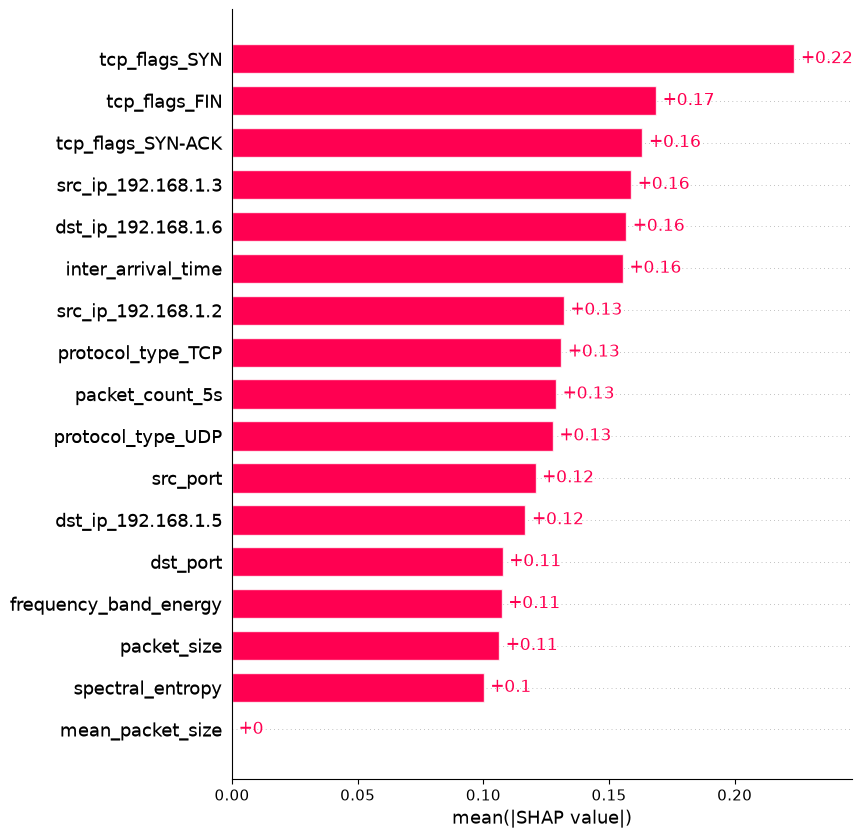

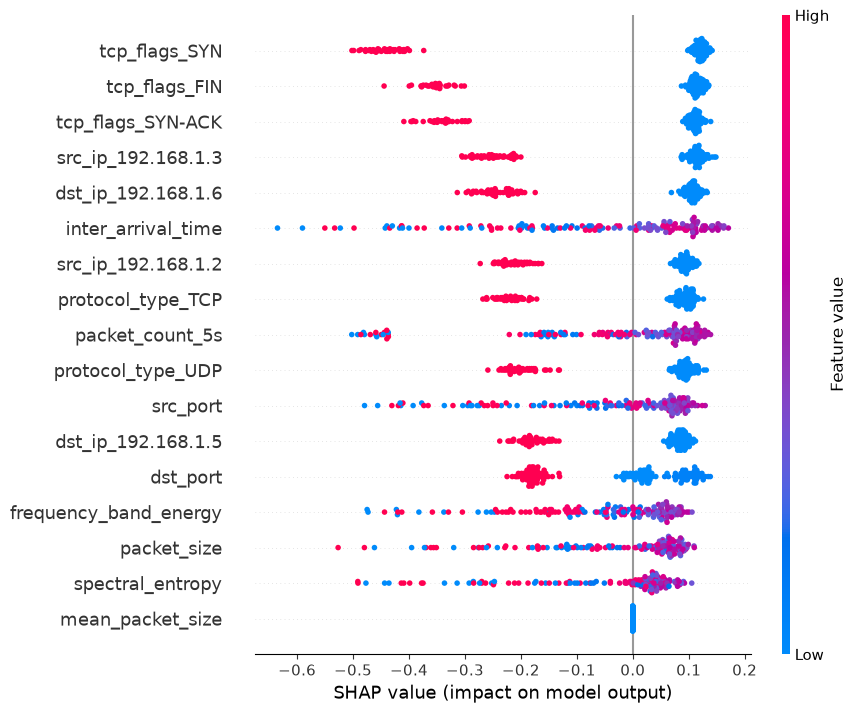

In [36]:
iforest = best_model.detector_            # underlying sklearn IsolationForest

explainer = shap.TreeExplainer(iforest)
shap_values = explainer(X_valid)          # explain the validation set

# Global feature importance: mean |SHAP| per feature
shap.plots.bar(shap_values, max_display=17)

# Distribution of each feature's effect across samples
shap.plots.beeswarm(shap_values, max_display=17)

In [ ]:
mean_abs_shap = pd.Series(
    np.abs(shap_values.values).mean(axis=0),
    index=X_valid.columns,
).sort_values(ascending=False)

print(mean_abs_shap)                 # names + values, high to low
print(mean_abs_shap.index.tolist())  # just the names, in order

# ['tcp_flags_SYN', 'tcp_flags_FIN', 'tcp_flags_SYN-ACK', 'src_ip_192.168.1.3', 'dst_ip_192.168.1.6', 'inter_arrival_time', 'src_ip_192.168.1.2', 'protocol_type_TCP', 'packet_count_5s', 'protocol_type_UDP', 'src_port', 'dst_ip_192.168.1.5', 'dst_port', 'frequency_band_energy', 'packet_size', 'spectral_entropy', 'mean_packet_size']

tcp_flags_SYN            0.223749
tcp_flags_FIN            0.168725
tcp_flags_SYN-ACK        0.163286
src_ip_192.168.1.3       0.158814
dst_ip_192.168.1.6       0.156845
inter_arrival_time       0.155512
src_ip_192.168.1.2       0.132013
protocol_type_TCP        0.131002
packet_count_5s          0.128926
protocol_type_UDP        0.127641
src_port                 0.120752
dst_ip_192.168.1.5       0.116742
dst_port                 0.107682
frequency_band_energy    0.107277
packet_size              0.106297
spectral_entropy         0.100129
mean_packet_size         0.000000
dtype: float64
['tcp_flags_SYN', 'tcp_flags_FIN', 'tcp_flags_SYN-ACK', 'src_ip_192.168.1.3', 'dst_ip_192.168.1.6', 'inter_arrival_time', 'src_ip_192.168.1.2', 'protocol_type_TCP', 'packet_count_5s', 'protocol_type_UDP', 'src_port', 'dst_ip_192.168.1.5', 'dst_port', 'frequency_band_energy', 'packet_size', 'spectral_entropy', 'mean_packet_size']


## Step 2: Determine the threshold
In practice, the true proportion of anomalies is unknown. Therefore, threshold selection is guided by the score distribution.

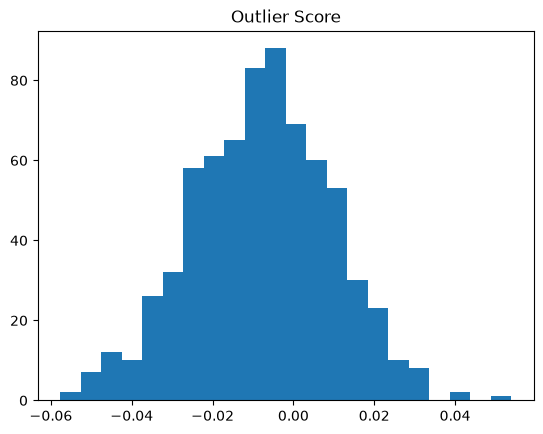

In [ ]:
y_train_scores = best_model.decision_function(X_train)
plot_hist(y_train_scores)

#### Option 1: Percentile of y_train_scores (no label needed)

In [60]:
actual_train_rate = (y_train == 1).mean() 
actual_valid_rate = (y_valid == 1).mean() 
est_expected_rate = (y_train_scores > 0.02).mean()
actual_train_rate, actual_valid_rate, est_expected_rate

(0.1, 0.1, 0.05285714285714286)

In [61]:
threshold = 0.02
y_valid_pred = (best_model.decision_function(X_valid) > threshold).astype(int)
format(y_valid_pred.mean(), ".4f")

'0.1067'

#### Option 2: use optuna param: contamination

In [38]:
print(f"Threshold from tuned best model: {best_model.threshold_}" )                # cutoff on decision_function scores
# best_model.labels_                    # 0/1 labels for X_train
y_valid_pred = best_model.predict(X_valid)   # 1 = outlier, uses threshold_

Threshold from tuned best model: -2.2874971773549635e-17


#### Option 3: tune it with valid data with labels

## Step 3: Descriptive statistics
- In practice, the threshold can be adjusted to achieve a more appropriate segmentation of the data. By
testing a range of threshold values, we can control the size of the outlier group and refine the balance
between sensitivity and precision. 
>> - 1. First, the size of the outlier group is directly determined by the selected threshold
>> - 2. Second, the feature-level statistics should be consistent with domain expectations.
>> - 3. Third, the average anomaly score of the outlier group should be substantially higher than that of the
normal group, indicating effective separation. 

In [64]:
descriptive_stat_threshold(X_train, y_train_scores, threshold)

,Group,Count,Count %,packet_size,inter_arrival_time,src_port,dst_port,packet_count_5s,mean_packet_size,spectral_entropy,...,protocol_type_TCP,protocol_type_UDP,src_ip_192.168.1.2,src_ip_192.168.1.3,dst_ip_192.168.1.5,dst_ip_192.168.1.6,tcp_flags_FIN,tcp_flags_SYN,tcp_flags_SYN-ACK,Anomaly_Score
0,Normal,663,94.714286,0.49,0.52,31870.61,197.19,0.50,0.0,0.49,...,0.31,0.35,0.32,0.32,0.34,0.32,0.25,0.22,0.25,-0.01
1,Outlier,37,5.285714,0.51,0.43,41274.24,188.97,0.53,0.0,0.39,...,0.46,0.43,0.49,0.43,0.35,0.49,0.43,0.27,0.22,0.03


## Step 4: Averages -- when there is no label for Optuna to work
- Although Isolation Forest is already an ensemble method, further aggregation can improve robustness.
- By training multiple models with different parameter settings and combining their predictions, we
reduce variance and improve stability.

In [74]:
# Standardize data
X_train_norm, X_test_norm = standardizer(X_train, X_valid)

In [72]:
X_train.shape, int(X_train.shape[0] * 0.1), int(X_train.shape[0] * 0.4), (int(X_train.shape[0] * 0.4)/int(X_train.shape[0] * 0.1))

((700, 17), 70, 280, 4.0)

In [77]:
# Test a range of maximum samples
# k_list = np.arange(int(X_train.shape[1] * 0.05), int(X_train.shape[1] * 0.4), 4) 
k_list = [100, 200, 300, 400, 500]
n_clf = len(k_list)
# Just prepare data frames so we can store the model results
train_scores = np.zeros([X_train.shape[0], n_clf])
test_scores = np.zeros([X_test.shape[0], n_clf])

# Modeling
for i in range(n_clf):
    k = k_list[i]
    #isft = IForest(contamination=0.05, max_samples=k)
    isft = IForest(contamination=0.1, n_estimators=k)
    isft.fit(X_train_norm)

    # Store the results in each column:
    train_scores[:, i] = isft.decision_function(X_train_norm)
    test_scores[:, i] = isft.decision_function(X_test_norm)
# Decision scores have to be normalized before combination
train_scores_norm, test_scores_norm = standardizer(train_scores,test_scores)

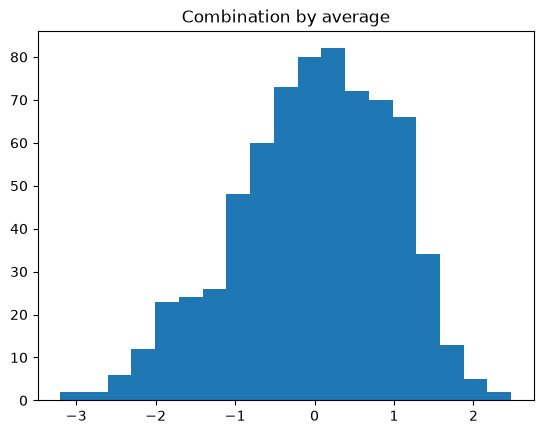

In [78]:
y_train_by_average = average(train_scores_norm)
y_test_by_average = average(test_scores_norm)

plot_hist(y_train_by_average, title="Combination by average")

In [83]:
descriptive_stat_threshold(X_train,y_train_by_average, 1.8)

,Group,Count,Count %,packet_size,inter_arrival_time,src_port,dst_port,packet_count_5s,mean_packet_size,spectral_entropy,...,protocol_type_TCP,protocol_type_UDP,src_ip_192.168.1.2,src_ip_192.168.1.3,dst_ip_192.168.1.5,dst_ip_192.168.1.6,tcp_flags_FIN,tcp_flags_SYN,tcp_flags_SYN-ACK,Anomaly_Score
0,Normal,691,98.714286,0.49,0.51,32182.17,195.81,0.50,0.0,0.49,...,0.31,0.35,0.33,0.33,0.34,0.33,0.26,0.22,0.25,-0.03
1,Outlier,9,1.285714,0.45,0.63,46609.11,269.67,0.47,0.0,0.20,...,0.67,0.33,0.56,0.44,0.22,0.67,0.33,0.33,0.33,2.06


In [84]:
descriptive_stat_threshold(X_test,y_test_by_average, 1.5)

,Group,Count,Count %,packet_size,inter_arrival_time,src_port,dst_port,packet_count_5s,mean_packet_size,spectral_entropy,...,protocol_type_TCP,protocol_type_UDP,src_ip_192.168.1.2,src_ip_192.168.1.3,dst_ip_192.168.1.5,dst_ip_192.168.1.6,tcp_flags_FIN,tcp_flags_SYN,tcp_flags_SYN-ACK,Anomaly_Score
0,Normal,137,91.333333,0.53,0.50,33639.96,189.38,0.50,0.0,0.48,...,0.31,0.37,0.26,0.39,0.33,0.37,0.23,0.21,0.28,0.11
1,Outlier,13,8.666667,0.55,0.41,28005.69,271.31,0.48,0.0,0.43,...,0.15,0.69,0.08,0.38,0.31,0.31,0.31,0.15,0.38,2.03
